**GitHub repository:** https://github.com/Enne08/ai-employment-analysis.git



# AI, Data Science and Software Development Employment in the USA (May 2023)

This notebook explores the U.S. Bureau of Labor Statistics (BLS) **Occupational Employment and Wage Statistics (OEWS)** data for May 2023, focusing on jobs involving AI, data science and software development.

**Data source:** https://www.bls.gov/oes/tables.htm ("All data", May 2023)

**Contents**
1. Setup and data loading
2. Data inspection
3. Data cleaning
4. Selecting AI-related occupations
5. Visualisations *(to follow)*
6. Challenge: trends over time *(to follow)*
7. Conclusions *(to follow)*

## 1. Setup and data loading

I use **pandas** for data handling and **matplotlib** and **seaborn** for the charts.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

The raw file is large (about 80 MB, more than 400,000 rows), so it is stored in a `data/` folder that is **not** uploaded to GitHub. To run this notebook, download `all_data_M_2023.xlsx` from the BLS page above and place it in `data/`.

Loading takes a minute or two.

In [2]:
DATA_PATH = "data/all_data_M_2023.xlsx"

raw = pd.read_excel(DATA_PATH)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## 2. Data inspection

First I check which columns are available and how the data is organised.

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

Key columns (from the BLS file layout):

| Column | Meaning |
|---|---|
| `AREA_TYPE` | 1 = U.S. national, 2 = state, 3 = territory, 4 = metropolitan area, 6 = non-metropolitan area |
| `PRIM_STATE` | State abbreviation |
| `I_GROUP` | Industry level: `cross-industry` means all industries combined |
| `NAICS_TITLE` | Industry name |
| `OCC_CODE` / `OCC_TITLE` | Occupation code and name |
| `O_GROUP` | Occupation level: `detailed`, `broad`, `minor`, `major`, `total` |
| `TOT_EMP` | Total employment |
| `A_MEAN`, `A_MEDIAN` | Mean and median annual wage |
| `A_PCT10` … `A_PCT90` | Annual wage percentiles |
| `LOC_QUOTIENT` | How concentrated the job is in an area compared with the U.S. average (1 = average) |

The file mixes several levels of detail. The same occupation appears once for the whole U.S., once per state, once per industry and so on. I have to filter carefully so that I don't double-count.

In [4]:
print("Area types:\n", raw["AREA_TYPE"].value_counts().sort_index(), "\n")
print("Industry groups:\n", raw["I_GROUP"].value_counts(), "\n")
print("Occupation groups:\n", raw["O_GROUP"].value_counts())

Area types:
 AREA_TYPE
1    177501
2     36643
3      1033
4    149591
6     48559
Name: count, dtype: int64 

Industry groups:
 I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64 

Occupation groups:
 O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64


## 3. Data cleaning

The numeric columns load as text because the BLS uses special symbols:

- `*` means the figure is not available
- `**` means employment could not be estimated
- `#` means the wage is at or above the top published value ($239,200 per year or $115 per hour)
- `~` means the figure is less than 0.5%

I convert these columns to numbers. Symbols become `NaN` (missing). For `#` I use the cap value of $239,200, because the real wage is *at least* that much. Dropping those rows would hide the highest earners.

In [5]:
df = raw.copy()

numeric_cols = ["TOT_EMP", "EMP_PRSE", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL",
                "H_MEAN", "A_MEAN", "H_MEDIAN", "A_MEDIAN",
                "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

ANNUAL_CAP = 239200
annual_wage_cols = ["A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

for col in numeric_cols:
    s = df[col].astype(str).str.strip()
    if col in annual_wage_cols:
        s = s.replace("#", str(ANNUAL_CAP))
    df[col] = pd.to_numeric(s.str.replace(",", ""), errors="coerce")

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
TOT_EMP,401729.0,12758.953075,360803.186348,30.000,100.000,320.00,1530.000,1.518539e+08
EMP_PRSE,401729.0,11.489593,10.038481,0.000,4.200,8.50,15.800,4.990000e+01
JOBS_1000,232193.0,7.384989,51.779168,0.002,0.413,1.05,2.961,1.000000e+03
LOC_QUOTIENT,232193.0,1.367247,2.735332,0.020,0.680,0.98,1.400,3.498200e+02
PCT_TOTAL,162584.0,1.346167,6.681308,0.000,0.020,0.11,0.550,1.000000e+02
H_MEAN,392363.0,32.475558,18.517677,8.050,20.610,27.19,38.740,3.533800e+02
A_MEAN,408244.0,68109.229603,38660.519950,16750.000,43210.000,57340.00,81430.000,1.805790e+06
H_MEDIAN,390268.0,29.804504,14.968021,7.250,19.100,25.10,36.430,1.149600e+02
A_MEDIAN,408244.0,63460.996610,33782.605405,15080.000,40160.000,53430.00,76970.000,2.392000e+05
A_PCT10,408244.0,42905.108367,20248.761249,15080.000,30350.000,37440.00,49250.000,2.392000e+05


## 4. Selecting AI-related occupations

The BLS has no single "AI" occupation code, so I chose the occupations that most closely match work in **AI, data science and software development**:

| Code | Occupation | Why it is included |
|---|---|---|
| 15-2051 | Data Scientists | Build machine-learning and predictive models; the core "AI" job |
| 15-1221 | Computer and Information Research Scientists | Research new computing methods, including AI and machine-learning algorithms |
| 15-1252 | Software Developers | Build the applications and systems that AI is deployed in |
| 15-1253 | Software Quality Assurance Analysts and Testers | Test software, including AI-powered products |
| 15-1211 | Computer Systems Analysts | Design systems and decide where technology such as AI fits into an organisation |
| 15-2031 | Operations Research Analysts | Use optimisation and statistical modelling, closely related to data science |

**Limitation:** these categories also include people who don't work on AI at all, especially among Software Developers. The data shows employment in AI-*related* fields, not AI jobs exactly.

In [6]:
AI_OCCUPATIONS = {
    "15-2051": "Data Scientists",
    "15-1221": "Computer & Info Research Scientists",
    "15-1252": "Software Developers",
    "15-1253": "Software QA Analysts & Testers",
    "15-1211": "Computer Systems Analysts",
    "15-2031": "Operations Research Analysts",
}

ai = df[df["OCC_CODE"].isin(AI_OCCUPATIONS)].copy()
ai["SHORT_TITLE"] = ai["OCC_CODE"].map(AI_OCCUPATIONS)
print("AI-related rows:", len(ai))

AI-related rows: 3681


Next I split the data into three tables, one for each level of detail I will chart:

- **`national`**: U.S. totals, all industries combined (one row per occupation)
- **`states`**: each of the 50 states plus DC, all industries combined
- **`industries`**: U.S. totals broken down by industry sector

In [7]:
cross = ai["I_GROUP"] == "cross-industry"

national = ai[(ai["AREA_TYPE"] == 1) & cross].sort_values("TOT_EMP", ascending=False)
states = ai[(ai["AREA_TYPE"] == 2) & cross]
industries = ai[(ai["AREA_TYPE"] == 1) & (ai["I_GROUP"] == "sector")]

print("National rows:", len(national))
print("State rows:", len(states), "| states per occupation:", states.groupby("OCC_CODE").size().unique())
print("Industry rows:", len(industries))

national[["OCC_CODE", "SHORT_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT90"]]

National rows: 6
State rows: 292 | states per occupation: [50 42 51 49]
Industry rows: 107


,OCC_CODE,SHORT_TITLE,TOT_EMP,A_MEAN,A_MEDIAN,A_PCT10,A_PCT90
149,15-1252,Software Developers,1656880.0,138110.0,132270.0,77020.0,208620.0
135,15-1211,Computer Systems Analysts,498810.0,110800.0,103800.0,63230.0,165700.0
150,15-1253,Software QA Analysts & Testers,203040.0,108460.0,101800.0,58740.0,164520.0
165,15-2051,Data Scientists,192710.0,119040.0,108020.0,61070.0,184090.0
161,15-2031,Operations Research Analysts,117880.0,95600.0,83640.0,52930.0,148920.0
138,15-1221,Computer & Info Research Scientists,35210.0,157160.0,145080.0,81450.0,233110.0


Not every occupation has 51 state rows. The BLS hides estimates when too few people are employed for a reliable figure (for example, Computer & Information Research Scientists appear in only 42 states). I need to remember this when comparing states.

A quick check of the totals before charting:

In [8]:
all_jobs = df.loc[(df["AREA_TYPE"] == 1) & (df["OCC_CODE"] == "00-0000"), "TOT_EMP"].iloc[0]
all_mean_wage = df.loc[(df["AREA_TYPE"] == 1) & (df["OCC_CODE"] == "00-0000"), "A_MEAN"].iloc[0]
ai_total = national["TOT_EMP"].sum()

print(f"Total U.S. employment:            {all_jobs:,.0f}")
print(f"AI-related employment:            {ai_total:,.0f}")
print(f"Share of all U.S. jobs:           {ai_total / all_jobs:.2%}")
print(f"Mean wage, all occupations:       ${all_mean_wage:,.0f}")
print(f"Mean wage range, AI-related jobs: ${national['A_MEAN'].min():,.0f} to ${national['A_MEAN'].max():,.0f}")

Total U.S. employment:            151,853,870
AI-related employment:            2,704,530
Share of all U.S. jobs:           1.78%
Mean wage, all occupations:       $65,470
Mean wage range, AI-related jobs: $95,600 to $157,160


Finally I save the three small tables as CSV files. They are only a few hundred KB, so they **can** be uploaded to GitHub, and the visualisation sections can load them quickly without re-reading the large Excel file.

In [10]:
import os
os.makedirs("data/processed", exist_ok=True)

keep = ["AREA_TITLE", "PRIM_STATE", "NAICS_TITLE", "OCC_CODE", "OCC_TITLE", "SHORT_TITLE",
        "TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEAN", "A_MEDIAN",
        "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

national[keep].to_csv("data/processed/ai_national_2023.csv", index=False)
states[keep].to_csv("data/processed/ai_states_2023.csv", index=False)
industries[keep].to_csv("data/processed/ai_industries_2023.csv", index=False)
print("Saved processed files to data/processed/")

Saved processed files to data/processed/


## 5. Visualisations

To make this section quick to run, I load the small processed CSV files saved in section 4 instead of the large Excel file.

In [2]:
national = pd.read_csv("data/processed/ai_national_2023.csv")
states = pd.read_csv("data/processed/ai_states_2023.csv")
industries = pd.read_csv("data/processed/ai_industries_2023.csv")

national = national.sort_values("TOT_EMP", ascending=False)
colours = dict(zip(national["SHORT_TITLE"], sns.color_palette("Set2", len(national))))
print("Loaded:", len(national), "occupations,", len(states), "state rows,", len(industries), "industry rows")

Loaded: 6 occupations, 292 state rows, 107 industry rows


### Visualisation 1: Employment by occupation (horizontal bar chart)

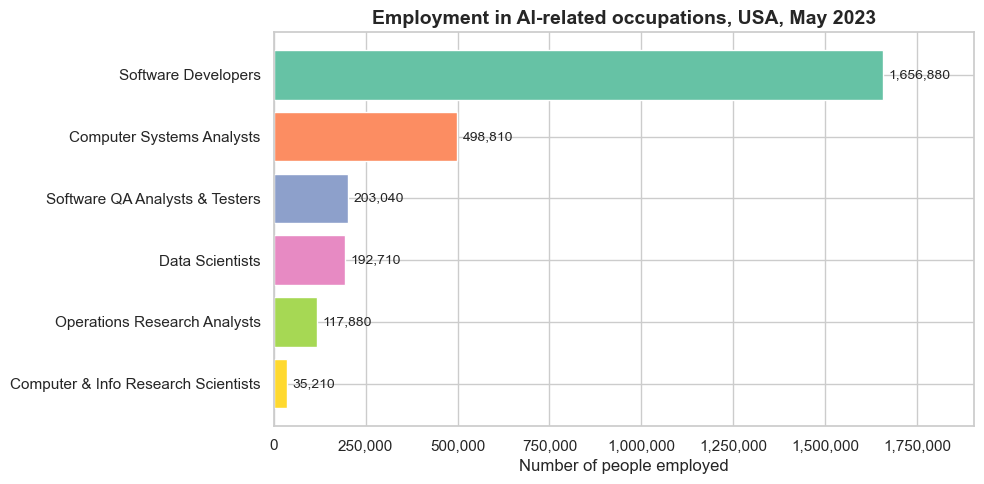

In [3]:
import matplotlib.ticker as mticker

data = national.sort_values("TOT_EMP")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(data["SHORT_TITLE"], data["TOT_EMP"],
               color=[colours[t] for t in data["SHORT_TITLE"]])

for bar in bars:
    value = bar.get_width()
    ax.text(value + 15000, bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}", va="center", fontsize=10)

ax.set_title("Employment in AI-related occupations, USA, May 2023", fontsize=14, weight="bold")
ax.set_xlabel("Number of people employed")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, data["TOT_EMP"].max() * 1.15)
plt.tight_layout()
plt.show()

**Objective:** Comparison. To compare how many people work in each AI-related occupation and see which roles make up most of the workforce.

**Why this chart type:** The data is one categorical variable (occupation) and one numerical variable (employment). A bar chart is the clearest way to compare amounts across categories, because the eye compares bar lengths easily. I used horizontal bars because the occupation names are long and stay readable on the y-axis. Sorting the bars from largest to smallest, and labelling each with its exact value, makes the ranking obvious at a glance.

**What I learned:**
- Software Developers dominate, with about **1.66 million** jobs, more than three times the next occupation (Computer Systems Analysts, about 499,000).
- Data Scientists, the job most directly linked to AI, employ about **193,000** people. That is only about one-ninth the number of Software Developers.
- Computer & Information Research Scientists, who carry out most AI research, are the smallest group at only **35,210** people. Cutting-edge AI work is done by a very small, specialised workforce.
- In total, these six occupations employ about **2.7 million** people, roughly **1.8%** of all U.S. jobs.

### Visualisation 2: Share of the AI-related workforce (donut chart)

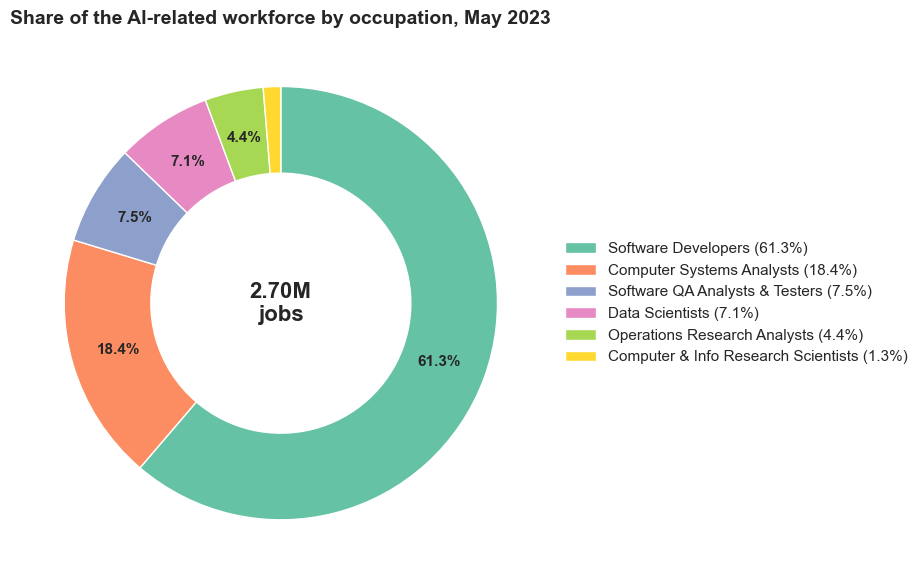

In [4]:
data = national.sort_values("TOT_EMP", ascending=False)
total = data["TOT_EMP"].sum()

fig, ax = plt.subplots(figsize=(12, 6))
wedges, texts, autotexts = ax.pie(
    data["TOT_EMP"],
    colors=[colours[t] for t in data["SHORT_TITLE"]],
    autopct=lambda p: f"{p:.1f}%" if p > 3 else "",
    pctdistance=0.78,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.4, edgecolor="white"),
)
for t in autotexts:
    t.set_fontsize(11)
    t.set_weight("bold")

ax.text(0, 0, f"{total/1e6:.2f}M\njobs", ha="center", va="center", fontsize=16, weight="bold")
labels = [f"{t} ({v / total:.1%})" for t, v in zip(data["SHORT_TITLE"], data["TOT_EMP"])]
ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Share of the AI-related workforce by occupation, May 2023", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

**Objective:** Composition. To show what proportion of the whole AI-related workforce each occupation makes up.

**Why this chart type:** The bar chart shows exact numbers, but it does not show clearly how each part relates to the whole. A pie chart shows parts of a whole, and it works here because there are only six categories that add up to 100%. I used a donut chart (a pie with a hole) so I could put the total, 2.70 million jobs, in the centre. I also kept the same colours as Visualisation 1 so the two charts are easy to connect. Percentages are labelled because people find it hard to judge angles exactly.

**What I learned:**
- Software Developers make up **61.3%** of the AI-related workforce on their own, and together with Computer Systems Analysts (18.4%) they make up almost **80%**.
- The roles most specialised in AI are a small slice: Data Scientists are **7.1%** and Computer & Information Research Scientists only **1.3%**.
- Most AI-related employment is therefore in building and running software systems, not in AI research itself. This suggests AI is mostly being *applied* through general software development roles.

### Visualisation 3: Wage distribution by occupation (box plot)

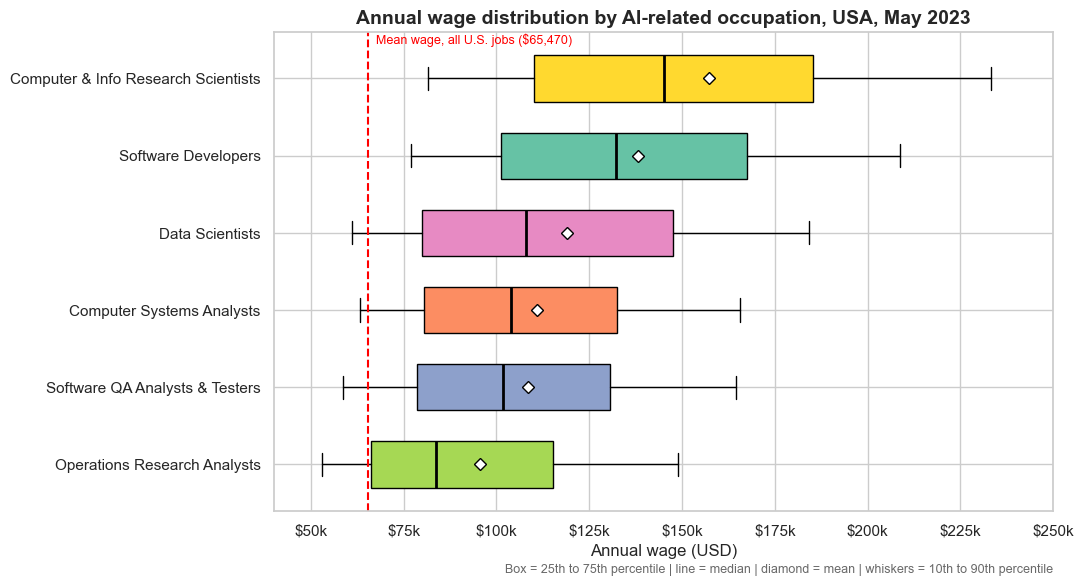

In [5]:
data = national.sort_values("A_MEDIAN", ascending=False)

box_stats = []
for _, row in data.iterrows():
    box_stats.append({
        "label": row["SHORT_TITLE"],
        "whislo": row["A_PCT10"],   # 10th percentile
        "q1": row["A_PCT25"],       # 25th percentile
        "med": row["A_MEDIAN"],     # median
        "q3": row["A_PCT75"],       # 75th percentile
        "whishi": row["A_PCT90"],   # 90th percentile
        "mean": row["A_MEAN"],
        "fliers": [],
    })

fig, ax = plt.subplots(figsize=(11, 6))
boxes = ax.bxp(box_stats, vert=False, showmeans=True, patch_artist=True, widths=0.6,
               meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
               medianprops=dict(color="black", linewidth=2))
for patch, title in zip(boxes["boxes"], data["SHORT_TITLE"]):
    patch.set_facecolor(colours[title])

all_mean = 65470
ax.axvline(all_mean, color="red", linestyle="--", linewidth=1.5)
ax.text(all_mean + 2000, 0.5, "Mean wage, all U.S. jobs ($65,470)", color="red", fontsize=9, va="center")

ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"${x/1000:.0f}k"))
ax.set_xlim(40000, 250000)
ax.set_ylim(len(data) + 0.6, 0.4)
ax.set_xlabel("Annual wage (USD)")
ax.set_title("Annual wage distribution by AI-related occupation, USA, May 2023", fontsize=14, weight="bold")
ax.text(1, -0.13, "Box = 25th to 75th percentile | line = median | diamond = mean | whiskers = 10th to 90th percentile",
        transform=ax.transAxes, ha="right", fontsize=9, color="dimgrey")
plt.tight_layout()
plt.show()

**Objective:** Distribution and comparison. To compare not just the average pay of each occupation but how spread out the wages are, from lower-paid to top earners.

**Why this chart type:** A box plot shows the whole spread of a numerical variable in one shape: the middle 50% of workers (the box), the median (the line) and the range (the whiskers). This lets me compare six wage distributions side by side, which a bar chart of averages cannot do. The BLS does not publish individual wages, only percentiles, so I built each box directly from the published 10th, 25th, 50th, 75th and 90th percentiles. The whiskers therefore show the 10th to 90th percentile, not the minimum and maximum. I added the mean (diamond) and a red line for the average U.S. wage as a reference point.

**What I learned:**
- **Every AI-related occupation pays well above average.** All six medians are above the U.S. mean wage of $65,470, and for Software Developers and Computer & Information Research Scientists even the **lowest-paid 10%** earn more than that ($77,020 and $81,450).
- **Computer & Information Research Scientists**, the group closest to AI research, earn the most (median **$145,080**), and their top 10% earn over **$233,000**.
- **Data Scientists** have a median of **$108,020** but a mean of **$119,040**. Because the mean is higher than the median, a group of very high earners is pulling the average up. Their wages are also very spread out ($61k to $184k), which probably reflects the gap between junior analysts and experienced machine-learning specialists.
- Operations Research Analysts are the lowest paid of the six (median **$83,640**), even though their work is mathematically similar to data science.

### Visualisation 4: Top 10 states for AI-related employment (ranked bar chart)

Top 10 states' share of AI-related jobs: 61%


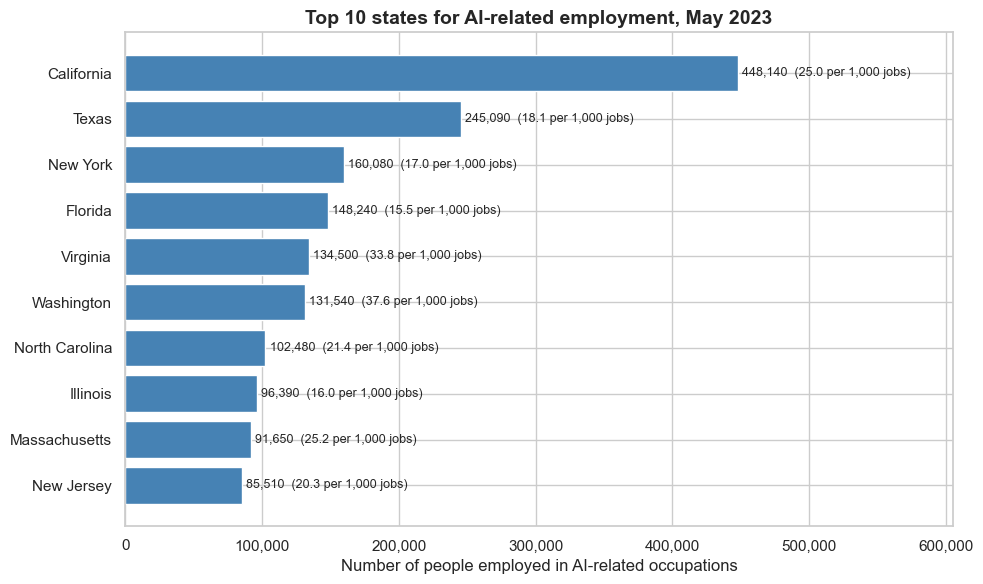

In [7]:
state_totals = (states.groupby(["AREA_TITLE", "PRIM_STATE"])
                .agg(AI_JOBS=("TOT_EMP", "sum"), AI_PER_1000=("JOBS_1000", "sum"))
                .reset_index())

top10 = state_totals.sort_values("AI_JOBS", ascending=False).head(10)
print(f"Top 10 states' share of AI-related jobs: {top10['AI_JOBS'].sum() / state_totals['AI_JOBS'].sum():.0%}")

data = top10.sort_values("AI_JOBS")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(data["AREA_TITLE"], data["AI_JOBS"], color="steelblue")
for bar, per1000 in zip(bars, data["AI_PER_1000"]):
    ax.text(bar.get_width() + 3000, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():,.0f}  ({per1000:.1f} per 1,000 jobs)", va="center", fontsize=9)

ax.set_title("Top 10 states for AI-related employment, May 2023", fontsize=14, weight="bold")
ax.set_xlabel("Number of people employed in AI-related occupations")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, data["AI_JOBS"].max() * 1.35)
plt.tight_layout()
plt.show()

### Visualisation 5: AI job concentration vs wages by state (scatter plot)

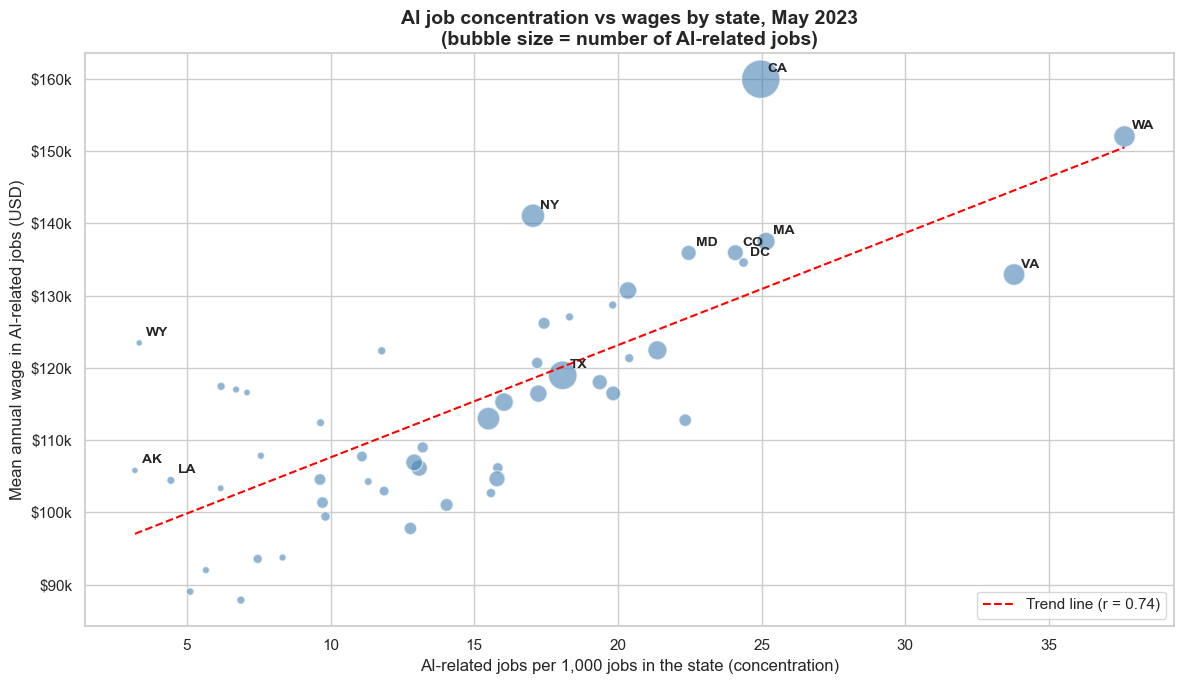

In [8]:
states["WAGE_BILL"] = states["TOT_EMP"] * states["A_MEAN"]
wages = states.dropna(subset=["TOT_EMP"]).groupby("AREA_TITLE")[["WAGE_BILL", "TOT_EMP"]].sum()
state_totals["AI_MEAN_WAGE"] = state_totals["AREA_TITLE"].map(wages["WAGE_BILL"] / wages["TOT_EMP"])

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(state_totals["AI_PER_1000"], state_totals["AI_MEAN_WAGE"],
           s=20 + state_totals["AI_JOBS"] / 600, alpha=0.6, color="steelblue", edgecolor="white")

label = pd.concat([state_totals.nlargest(6, "AI_PER_1000"), state_totals.nlargest(6, "AI_MEAN_WAGE"),
                   state_totals.nlargest(3, "AI_JOBS"), state_totals.nsmallest(3, "AI_PER_1000")]).drop_duplicates()
for _, r in label.iterrows():
    ax.annotate(r["PRIM_STATE"], (r["AI_PER_1000"], r["AI_MEAN_WAGE"]),
                xytext=(5, 5), textcoords="offset points", fontsize=10, weight="bold")

r = state_totals["AI_PER_1000"].corr(state_totals["AI_MEAN_WAGE"])
m, b = np.polyfit(state_totals["AI_PER_1000"], state_totals["AI_MEAN_WAGE"], 1)
xs = np.linspace(state_totals["AI_PER_1000"].min(), state_totals["AI_PER_1000"].max(), 50)
ax.plot(xs, m * xs + b, color="red", linestyle="--", linewidth=1.5, label=f"Trend line (r = {r:.2f})")

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"${x/1000:.0f}k"))
ax.set_xlabel("AI-related jobs per 1,000 jobs in the state (concentration)")
ax.set_ylabel("Mean annual wage in AI-related jobs (USD)")
ax.set_title("AI job concentration vs wages by state, May 2023\n(bubble size = number of AI-related jobs)",
             fontsize=14, weight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Objective:** Relationship. To investigate whether states with more AI-related jobs (relative to their size) also pay those workers more.

**Why this chart type:** I am comparing two numerical variables for each of the 51 states, which is exactly what a scatter plot is for: each dot is one state, and the overall pattern shows whether the variables are related. I used jobs *per 1,000* instead of the total number so that large states do not automatically come out on top. The total number of jobs is shown as a third variable through the bubble size. A trend line and the correlation coefficient (r) measure how strong the relationship is. I labelled only the most interesting states to keep the chart readable.

**What I learned:**
- There is a **strong positive relationship (r = 0.74)**: states where AI-related work is more concentrated also tend to pay more. This suggests tech hubs compete for skilled workers, which pushes wages up.
- **California** has the highest mean wage (about **$160k**), and **Washington** has both the highest concentration (**37.6 per 1,000**) and the second-highest wage (about **$152k**).
- Some states break the pattern. **New York** pays well (about $141k) with only moderate concentration, probably because of high living costs and the finance sector. **Virginia** has very high concentration but lower wages (about $133k) than the trend line suggests, possibly because many jobs are in government-related work, which tends to pay less than big tech.
- States such as Alaska, Wyoming and Louisiana have very few AI-related jobs (3–4 per 1,000), and wages there are mostly lower.
- **Limitation:** correlation does not prove causation. Higher living costs in tech hubs also raise wages.

##  Challenge: AI-related employment trends, 2019–2023

To see how AI-related employment has changed over time, I downloaded the "All data" files for May 2019, 2020, 2021 and 2022 from the same BLS page (https://www.bls.gov/oes/tables.htm) and combined them with the 2023 data.

**A problem with the job codes:** the BLS changed its occupation codes in 2021, so the same job does not always have the same code in every year:
- In 2019 and 2020, **Software Developers** and **Software QA Testers** were one combined occupation (15-1256). From 2021 they are split (15-1252 and 15-1253).
- In 2019 and 2020, **Data Scientists** were grouped with other maths jobs as "Data Scientists and Mathematical Science Occupations, All Other" (15-2098). From 2021 they have their own code (15-2051).

To compare the years fairly, I combined Software Developers and QA Testers into one group for every year, and mapped both old and new Data Scientist codes to one group. The other three occupations kept the same code in all five years.

Reading five large Excel files is slow, so this cell only keeps the national rows I need and saves them to a small CSV file.

In [10]:
GROUPS = {
    "15-1256": "Software Developers & QA Testers",   # 2019-2020 code
    "15-1252": "Software Developers & QA Testers",   # 2021+ code
    "15-1253": "Software Developers & QA Testers",   # 2021+ code
    "15-1211": "Computer Systems Analysts",
    "15-2098": "Data Scientists",                    # 2019-2020 code
    "15-2051": "Data Scientists",                    # 2021+ code
    "15-2031": "Operations Research Analysts",
    "15-1221": "Computer & Info Research Scientists",
}

yearly = []
for year in [2019, 2020, 2021, 2022, 2023]:
    print("Loading", year, "...")
    d = pd.read_excel(f"data/all_data_M_{year}.xlsx")
    d.columns = d.columns.str.upper()   # the 2019 file uses lowercase column names

    d = d[(d["AREA_TYPE"] == 1) & (d["I_GROUP"] == "cross-industry")
          & (d["OCC_CODE"].isin(list(GROUPS) + ["00-0000"]))].copy()

    for col in ["TOT_EMP", "A_MEAN"]:
        d[col] = pd.to_numeric(d[col].astype(str).str.replace(",", ""), errors="coerce")

    d["YEAR"] = year
    yearly.append(d[["YEAR", "OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]])

trend_raw = pd.concat(yearly)
trend_raw.to_csv("data/processed/ai_trend_raw_2019_2023.csv", index=False)
print("Done:", len(trend_raw), "rows saved")

Loading 2019 ...
Loading 2020 ...
Loading 2021 ...
Loading 2022 ...
Loading 2023 ...
Done: 33 rows saved


## Next I combine the occupations into the five groups for each year. For the groups made of two occupations, the mean wage is a weighted average, so larger occupations count more. I also compare the total with all U.S. jobs.

In [13]:
trend_raw = pd.read_csv("data/processed/ai_trend_raw_2019_2023.csv", dtype={"OCC_CODE": str})

all_jobs = trend_raw[trend_raw["OCC_CODE"] == "00-0000"].set_index("YEAR")["TOT_EMP"]

ai_trend = trend_raw[trend_raw["OCC_CODE"] != "00-0000"].copy()
ai_trend["GROUP"] = ai_trend["OCC_CODE"].map(GROUPS)
ai_trend["WAGE_BILL"] = ai_trend["TOT_EMP"] * ai_trend["A_MEAN"]

trend = (ai_trend.groupby(["YEAR", "GROUP"])
         .agg(TOT_EMP=("TOT_EMP", "sum"), WAGE_BILL=("WAGE_BILL", "sum"))
         .reset_index())
trend["A_MEAN"] = trend["WAGE_BILL"] / trend["TOT_EMP"]

emp = trend.pivot(index="YEAR", columns="GROUP", values="TOT_EMP")
wage = trend.pivot(index="YEAR", columns="GROUP", values="A_MEAN").round(-1)

total_ai = emp.sum(axis=1)
summary = pd.DataFrame({"AI-related jobs": total_ai,
                        "All U.S. jobs": all_jobs,
                        "AI share of all jobs (%)": (total_ai / all_jobs * 100).round(2)})
summary

,AI-related jobs,All U.S. jobs,AI share of all jobs (%)
YEAR,,,
2019,2157200,146875480,1.47
2020,2237370,139099570,1.61
2021,2294970,140886310,1.63
2022,2534910,147886000,1.71
2023,2704530,151853870,1.78
